# Forecasting Search-Visibility Decline for Content Review Prioritization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amarkosovac11/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

**Lane:** Refresh / Content Opportunity Scoring  
**Release:** `flyrank_pseudonymized_warehouse_release_v20260703`

## Abstract

This study asks whether historical page-level search signals can prioritize pages for content review. It uses the gated FlyRank warehouse release at the client-page-month grain, with development centered on March 2026 and June 2026 reserved as the sealed final outcome period. A transparent demand-and-deterioration rule is compared with regularized logistic regression using identical held-out rows and ranking metrics. Final model-versus-baseline values are reported only when an authorized run produces the metric receipt. The output is a decision-support queue with reason codes and action labels, not a claim that refreshing content causes recovery.

In [1]:
# Fresh Colab setup: uncomment if dependencies are missing.
# %pip install -q -r ../../requirements.txt
import json, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
repo = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'work'/'capstone_pipeline.py').exists()), None)
if repo is None: raise FileNotFoundError('Run from a clone of this repository.')
sys.path.insert(0, str(repo/'work')); os.chdir(repo)
from capstone_pipeline import FEATURE_COLUMNS, RELEASE, WINDOWS, run_remote
print('Repository:', repo); print('Release:', RELEASE); print('Feature count:', len(FEATURE_COLUMNS))

Repository: E:\amar\flyrank\flyrank-ml-internship
Release: flyrank_pseudonymized_warehouse_release_v20260703
Feature count: 8


## 1. Question and decision

**Research question:** Can pre-outcome page-level search signals rank pages that will experience a material next-month decline in observed search impressions more precisely than a transparent rule?

One row is a pseudonymized client-page snapshot. The action is manual review, not automatic editing. False positives waste editorial time; false negatives may leave an observed decline unreviewed. The target forecasts decline risk and does **not** measure refresh uplift.

## 2. Data, release, windows, and exclusions

The analysis reads `fact_content_daily_performance` through DuckDB and aggregates remotely. Eligible snapshots have at least 20 GSC-available days in both months and at least 100 feature-month impressions. January→February and February→March train the first model; March→April is development validation; April→May is added for refitting; May→June is the sealed final test.

Identifiers are used only for joins and overlap audits. Client names, domains, URLs, titles, raw queries, product decisions, credentials, and future-window fields are excluded from model features.

In [2]:
window_table = pd.DataFrame([{'role': n, 'feature_month': f, 'outcome_month': o} for n,(f,o) in WINDOWS.items()])
display(window_table)
assert (window_table.feature_month < window_table.outcome_month).all()
assert WINDOWS['development_2026_03'] == ('2026-03','2026-04')
assert WINDOWS['sealed_test_2026_05'][1] == '2026-06'
print('Temporal contract verified.')

,role,feature_month,outcome_month
0,train_2026_01,2026-01,2026-02
1,train_2026_02,2026-02,2026-03
2,development_2026_03,2026-03,2026-04
3,refit_2026_04,2026-04,2026-05
4,sealed_test_2026_05,2026-05,2026-06


Temporal contract verified.


## 3. Methodology, target, baseline, and validation

`target_future_decline = 1` when next-month impressions are no more than 80% of feature-month impressions. Features are log impressions, CTR, impression-weighted average position, availability counts, and within-month impression/click momentum—all computed before the outcome month.

The baseline combines demand, recent deterioration, positions 4–20, and low CTR. The model is median imputation, standardization, and class-balanced regularized logistic regression (seed 42). Both methods use identical held-out rows. Primary metrics are Precision@20 and Precision@50; average precision, ROC AUC, and base rate add context. The final split is time-aware and reports client overlap; it is not an unseen-client claim.

In [3]:
forbidden={'client_hash_id','content_hash_id','y_impressions','future_impression_ratio','target_future_decline'}
assert forbidden.isdisjoint(FEATURE_COLUMNS)
print('Leakage feature audit passed. Features:', ', '.join(FEATURE_COLUMNS))
# Opt-in prevents repeated scans or accidental peeking. Set both variables only for the final run.
if os.getenv('RUN_WAREHOUSE') == '1':
    run_remote(repo/'work'/'outputs'); print('Authorized warehouse run completed.')
else:
    print('Warehouse scan skipped: set HF_TOKEN securely and RUN_WAREHOUSE=1.')

Leakage feature audit passed. Features: log_impressions, ctr, avg_position, active_days, click_days, position_days, impression_momentum, click_momentum
Warehouse scan skipped: set HF_TOKEN securely and RUN_WAREHOUSE=1.


## 4. Actual model-versus-baseline results

The table and plot below appear only from a verified metric receipt. If the receipt is absent, the notebook reports the evaluation as pending rather than inventing results.

,base_rate,precision_at_20,precision_at_50,average_precision,roc_auc
method,,,,,
Transparent baseline,0.641,0.95,0.98,0.703,0.554
Logistic regression,0.641,0.90,0.92,0.766,0.654


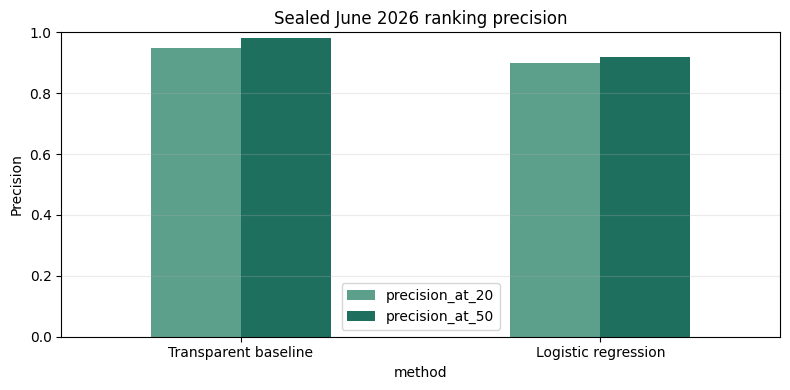

In [4]:
metrics_path=repo/'work'/'outputs'/'capstone_metrics.json'
if metrics_path.exists():
    receipt=json.loads(metrics_path.read_text(encoding='utf-8')); assert receipt['status']=='verified_warehouse_run'
    final=receipt['sealed_final']
    results=pd.DataFrame([{'method':'Transparent baseline',**final['baseline']},{'method':'Logistic regression',**final['model']}]).set_index('method')
    display(results[['base_rate','precision_at_20','precision_at_50','average_precision','roc_auc']].round(3))
    ax=results[['precision_at_20','precision_at_50']].plot.bar(ylim=(0,1),rot=0,color=['#5c9f8b','#1f6f5f'],figsize=(8,4))
    ax.set_ylabel('Precision'); ax.set_title('Sealed June 2026 ranking precision'); ax.grid(axis='y',alpha=.25); plt.tight_layout()
    figure_dir=repo/'work'/'figures'; figure_dir.mkdir(parents=True,exist_ok=True); plt.savefig(figure_dir/'sealed_precision.png',dpi=160,bbox_inches='tight'); plt.show()
else:
    status=json.loads((repo/'work'/'outputs'/'capstone_status.json').read_text(encoding='utf-8')); display(pd.DataFrame([status])); print('VERIFIED INCOMPLETE: no warehouse metrics or plot are claimed.')

## 5. Limitations and honest interpretation

This system forecasts measured search visibility. It does not identify Google's ranking algorithm, diagnose why impressions changed, or estimate the causal effect of editing a page. Demand, seasonality, indexing, SERP changes, query mix, site changes, and coverage can drive the outcome. The panel is unbalanced, the 20% decline cutoff is a decision convention, and a recurring-client temporal split does not establish performance for unseen clients.

If ML does not beat the baseline on the sealed period, the baseline remains the preferred method. A negative comparison is still a valid finding.

## 6. Ranked recommendations and action playbook

The private, gitignored runtime queue contains rank, pseudonymous join keys, scores, one reason code, an action label, and a limitation. Public outputs contain aggregates only.

- `RECENT_VISIBILITY_DECAY` → review freshness and relevance; first check demand changes.
- `REACHABLE_SEARCH_POSITION` → review coverage and intent fit.
- `LOW_CTR_WITH_DEMAND` → review snippet and intent alignment.
- `MULTIVARIATE_DECLINE_RISK` → inspect combined evidence before acting.

Never automate publishing, deletion, rewriting, or client communication from this queue.

In [5]:
summary_path=repo/'work'/'outputs'/'recommendation_summary.json'
if summary_path.exists(): display(pd.read_json(summary_path))
else: print('Recommendation summary pending the authorized warehouse run.')

,reason_code,action_label,recommendations,mean_model_score
0,LOW_CTR_WITH_DEMAND,REVIEW_SNIPPET_AND_INTENT,28560,0.514351
1,MULTIVARIATE_DECLINE_RISK,REVIEW_FRESHNESS_AND_RELEVANCE,147,0.205291
2,REACHABLE_SEARCH_POSITION,REVIEW_CONTENT_COVERAGE,744,0.197799
3,REACHABLE_SEARCH_POSITION,REVIEW_SNIPPET_AND_INTENT,44822,0.485154
4,RECENT_VISIBILITY_DECAY,REVIEW_CONTENT_COVERAGE,181,0.255815
5,RECENT_VISIBILITY_DECAY,REVIEW_FRESHNESS_AND_RELEVANCE,29,0.269578
6,RECENT_VISIBILITY_DECAY,REVIEW_SNIPPET_AND_INTENT,18565,0.542975


## 7. Reproducibility and artifacts

Run `python -m pip install -r requirements.txt`, set `HF_TOKEN` through an environment variable or Colab Secret, set `RUN_WAREHOUSE=1`, and run this notebook top to bottom once. The metric receipt is `work/outputs/capstone_metrics.json`; the row-level CSV remains ignored. The public paper lives under `paper/`. Seed: 42.

## 8. Acknowledgments

[Built on the FlyRank ML Internship dataset](https://flyrank.ai).

## ML-12 communication cuts

**Five-minute demo:** decision and non-causal target (45s); data windows and leakage guards (60s); baseline and model (60s); sealed comparison (75s); queue and limitations (60s).

**Social-post cut:** I built a reproducible content-review prioritization study using time-ordered search data, a transparent baseline, and a readable ML model. The work keeps June 2026 sealed, compares methods on the same rows, and turns forecasts into human-review reason codes—without claiming that edits cause recovery.

**Employer-facing summary:** I translated an ambiguous SEO prioritization problem into a leakage-aware temporal ML evaluation. I built a reproducible DuckDB-to-scikit-learn pipeline with metric receipts and public-safe outputs. I also designed the handoff so incomplete data access produces an explicit pending state instead of fabricated findings.

## Self-check

- [x] Complete question, data, method, limitations, recommendations, and reproducibility sections
- [x] No client names, URLs, raw queries, or credentials
- [x] Careful observed/directional/decision-support claims
- [x] Abstract, linked acknowledgment, and ML-12 cuts included
- [ ] Authorized warehouse run completed and sealed metrics verified
- [ ] Paper deployed after approval and direct URL recorded